<a href="https://colab.research.google.com/github/vtu27065/Deep-Learning/blob/main/Use%20Case%201%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PyTorch version: 2.11.0+cpu
Using device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 140MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 34.2MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 150MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.75MB/s]


Number of training images: 60000


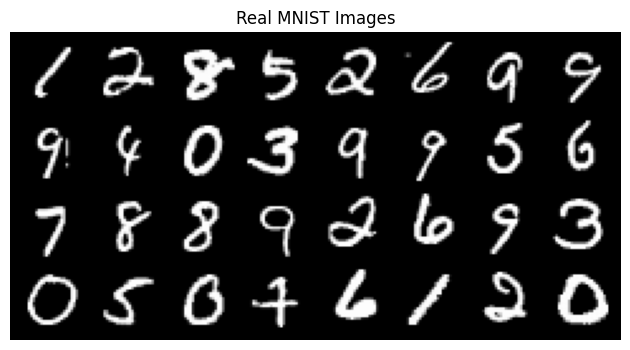

Image size: 784
Random noise size: 100
Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU(inplace=True)
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Tanh()
  )
)
Discriminator(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2, inplace=True)
    (4): Linear(in_features=256, out_features=1, bias=True)
    (5): Sigmoid()
  )
)
Loss function and optimizers are ready.
Fixed noise created for image generation.
Epoch [1/5] | Generator Loss: 1.5521 | Discriminator Loss: 0.8491
Epoch [2/5] | Generator Loss: 3.0386 | Discriminator Loss: 0.4520
Epoch [3/5] | Generator Loss: 3.8381 | Discriminator Loss: 0.3340
Epoch [4/5] | Generator Loss: 

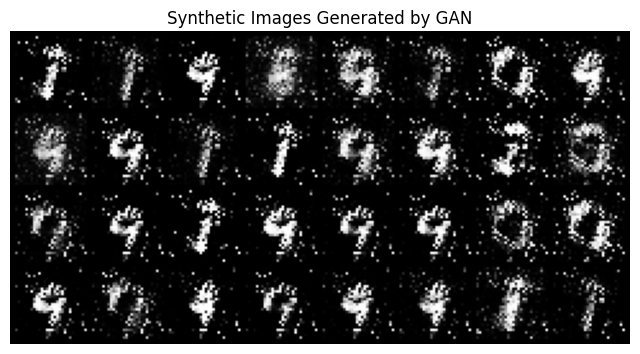

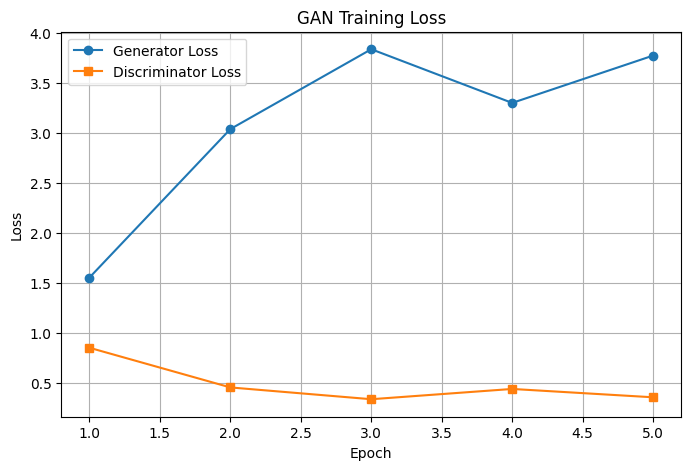

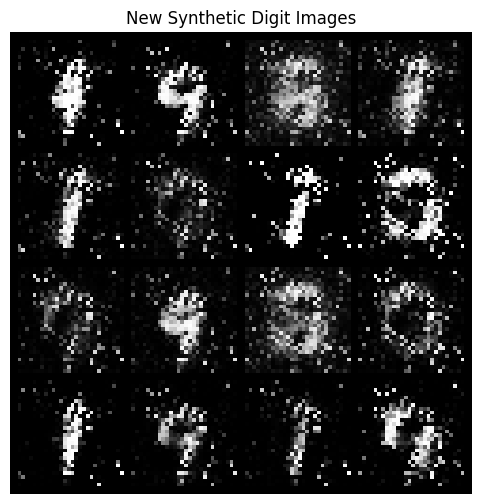

Saved 16 synthetic images in the 'synthetic_images' folder.
Synthetic image generation completed using PyTorch GAN.
The Generator creates digit-like images from random noise.
The Discriminator learns to distinguish real and generated images.


In [2]:
# Step 1: Import the required libraries


# Code cell 3
# Cell 3 of 32

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import torchvision.utils as vutils
import os
import random
import numpy as np

print("PyTorch version:", torch.__version__)

# Step 2: Set random seeds and select the device
# Cell 4 of 32

# Step 2: Set random seeds and select the device


# Code cell 5
# Cell 5 of 32

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Step 3: Load and prepare the MNIST dataset
# Cell 6 of 32

# Step 3: Load and prepare the MNIST dataset


# Code cell 7
# Cell 7 of 32

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True, num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Number of training images:", len(train_dataset))

# Step 4: Display sample real images
# Cell 8 of 32

# Step 4: Display sample real images


# Code cell 9
# Cell 9 of 32

real_images, _ = next(iter(train_loader))

plt.figure(figsize=(8, 4))
plt.axis("off")
plt.title("Real MNIST Images")
plt.imshow(
    np.transpose(vutils.make_grid(real_images[:32], padding=2, normalize=True),
                 (1, 2, 0))
)
plt.show()

# Step 5: Set the model parameters
# Cell 10 of 32

# Step 5: Set the model parameters


# Code cell 11
# Cell 11 of 32

image_size = 28 * 28
noise_size = 100
hidden_size = 256
batch_size = 128

print("Image size:", image_size)
print("Random noise size:", noise_size)

# Step 6: Define the Generator
# Cell 12 of 32

# Step 6: Define the Generator


# Code cell 13
# Cell 13 of 32

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(noise_size, hidden_size),
            nn.ReLU(True),
            nn.Linear(hidden_size, hidden_size * 2),
            nn.ReLU(True),
            nn.Linear(hidden_size * 2, image_size),
            nn.Tanh()
        )

    def forward(self, noise):
        image = self.model(noise)
        return image.view(-1, 1, 28, 28)

generator = Generator().to(device)
print(generator)

# Step 7: Define the Discriminator
# Cell 14 of 32

# Step 7: Define the Discriminator


# Code cell 15
# Cell 15 of 32

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(image_size, hidden_size * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(hidden_size * 2, hidden_size),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(hidden_size, 1),
            nn.Sigmoid()
        )

    def forward(self, image):
        image = image.view(-1, image_size)
        return self.model(image)

discriminator = Discriminator().to(device)
print(discriminator)

# Step 8: Define loss function and optimizers
# Cell 16 of 32

# Step 8: Define loss function and optimizers


# Code cell 17
# Cell 17 of 32

criterion = nn.BCELoss()

generator_optimizer = optim.Adam(
    generator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
discriminator_optimizer = optim.Adam(
    discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)

print("Loss function and optimizers are ready.")

# Step 9: Create fixed random noise for monitoring
# Cell 18 of 32

# Step 9: Create fixed random noise for monitoring


# Code cell 19
# Cell 19 of 32

fixed_noise = torch.randn(32, noise_size, device=device)

real_label = 1.0
fake_label = 0.0

generator_losses = []
discriminator_losses = []

print("Fixed noise created for image generation.")

# Step 10: Train the GAN
# Cell 20 of 32

# Step 10: Train the GAN


# Code cell 21
# Cell 21 of 32

num_epochs = 5

for epoch in range(num_epochs):
    g_running_loss = 0.0
    d_running_loss = 0.0

    for real_images, _ in train_loader:
        real_images = real_images.to(device)
        current_batch = real_images.size(0)

        real_targets = torch.full((current_batch, 1), real_label, device=device)
        fake_targets = torch.full((current_batch, 1), fake_label, device=device)

        # Train the Discriminator on real images.
        discriminator_optimizer.zero_grad()
        real_output = discriminator(real_images)
        real_loss = criterion(real_output, real_targets)

        # Generate fake images and train the Discriminator on them.
        noise = torch.randn(current_batch, noise_size, device=device)
        fake_images = generator(noise)
        fake_output = discriminator(fake_images.detach())
        fake_loss = criterion(fake_output, fake_targets)

        d_loss = real_loss + fake_loss
        d_loss.backward()
        discriminator_optimizer.step()

        # Train the Generator to fool the Discriminator.
        generator_optimizer.zero_grad()
        noise = torch.randn(current_batch, noise_size, device=device)
        generated_images = generator(noise)
        output = discriminator(generated_images)
        g_loss = criterion(output, real_targets)
        g_loss.backward()
        generator_optimizer.step()

        g_running_loss += g_loss.item()
        d_running_loss += d_loss.item()

    avg_g_loss = g_running_loss / len(train_loader)
    avg_d_loss = d_running_loss / len(train_loader)
    generator_losses.append(avg_g_loss)
    discriminator_losses.append(avg_d_loss)

    print(f"Epoch [{epoch + 1}/{num_epochs}] | "
          f"Generator Loss: {avg_g_loss:.4f} | "
          f"Discriminator Loss: {avg_d_loss:.4f}")

# Step 11: Generate synthetic images
# Cell 22 of 32

# Step 11: Generate synthetic images


# Code cell 23
# Cell 23 of 32

generator.eval()

with torch.no_grad():
    synthetic_images = generator(fixed_noise).cpu()

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Synthetic Images Generated by GAN")
plt.imshow(
    np.transpose(vutils.make_grid(
        synthetic_images, padding=2, normalize=True, nrow=8
    ), (1, 2, 0))
)
plt.show()

# Step 12: Plot training losses
# Cell 24 of 32

# Step 12: Plot training losses


# Code cell 25
# Cell 25 of 32

plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), generator_losses, marker="o",
         label="Generator Loss")
plt.plot(range(1, num_epochs + 1), discriminator_losses, marker="s",
         label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(True)
plt.show()

# Step 13: Generate a new set of images
# Cell 26 of 32

# Step 13: Generate a new set of images


# Code cell 27
# Cell 27 of 32

new_noise = torch.randn(16, noise_size, device=device)

with torch.no_grad():
    new_images = generator(new_noise).cpu()

plt.figure(figsize=(6, 6))
plt.axis("off")
plt.title("New Synthetic Digit Images")
plt.imshow(
    np.transpose(vutils.make_grid(
        new_images, padding=2, normalize=True, nrow=4
    ), (1, 2, 0))
)
plt.show()

# Step 14: Save the generated images
# Cell 28 of 32

# Step 14: Save the generated images


# Code cell 29
# Cell 29 of 32

os.makedirs("synthetic_images", exist_ok=True)

for i, image in enumerate(new_images):
    # Convert normalized tensor values to the range [0, 1].
    image_to_save = (image + 1) / 2
    plt.imsave(
        f"synthetic_images/generated_{i + 1}.png",
        image_to_save.squeeze().numpy(),
        cmap="gray"
    )

print("Saved 16 synthetic images in the 'synthetic_images' folder.")

# Step 15: Result
# Cell 30 of 32

# Step 15: Result


# Code cell 31
# Cell 31 of 32

print("Synthetic image generation completed using PyTorch GAN.")
print("The Generator creates digit-like images from random noise.")
print("The Discriminator learns to distinguish real and generated images.")